# Employee Engagement, Satisfaction & Burnout Diagnostic Analysis
### Palo Alto Networks | Unified Mentor Project

**Goal:** Build an early-warning HR diagnostic: an Engagement Index, a Burnout Risk Score, and workload / career-stage insights, so HR can act *before* employees decide to leave.

**Steps in this notebook**
1. Load and validate the data
2. Build the Engagement Index (standardized)
3. Identify burnout risk (Low / Medium / High)
4. Build the five KPIs
5. Workload and stress analysis
6. Career-stage analysis (including stagnation)
7. Engagement vs attrition (context only)
8. Manager action list and recommendations

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
df = pd.read_csv('Palo Alto Networks.csv')   
print(df.shape)
df.head()

(1470, 31)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


## 1. Data Validation & Normalization
We check missing values, duplicates, and that every 1-4 rating column really only contains 1, 2, 3 or 4.

In [3]:
print('Missing values :', int(df.isna().sum().sum()))
print('Duplicate rows :', int(df.duplicated().sum()))

ordinal_cols = ['JobInvolvement','JobSatisfaction','EnvironmentSatisfaction',
                'RelationshipSatisfaction','WorkLifeBalance']
for c in ordinal_cols:
    bad = (~df[c].isin([1,2,3,4])).sum()
    print(f'{c:28s} invalid values: {bad}  | values: {sorted(df[c].unique())}')

# Attrition should be 0/1 and OverTime Yes/No
print('Attrition values:', df.Attrition.unique(), '| OverTime values:', df.OverTime.unique())
print(f'Overall attrition rate: {df.Attrition.mean():.1%}')

Missing values : 0
Duplicate rows : 0
JobInvolvement               invalid values: 0  | values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
JobSatisfaction              invalid values: 0  | values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
EnvironmentSatisfaction      invalid values: 0  | values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
RelationshipSatisfaction     invalid values: 0  | values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
WorkLifeBalance              invalid values: 0  | values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Attrition values: [1 0] | OverTime values: ['Yes' 'No']
Overall attrition rate: 16.1%


**What this tells us:** the data is clean. There are no missing values, so no imputation is needed. In a real project with gaps, we would fill missing satisfaction scores with the **median** (the middle value, which is not distorted by extremes). All rating scales are valid 1-4.

## 2. Engagement Index Construction
We combine four survey ratings: **JobInvolvement, JobSatisfaction, EnvironmentSatisfaction, RelationshipSatisfaction**.

**Why standardize?** A *z-score* says "how many standard deviations above or below the company average is this person?" (`z = (value - mean) / std`). Putting every rating on the same scale means no single question dominates. We average the four z-scores, then rescale to **0-100** so HR can read it easily (50 is roughly the middle).

count    1470.0
mean       54.1
std        17.3
min         0.0
25%        43.7
50%        56.0
75%        64.3
max       100.0
Name: EngagementIndex, dtype: float64


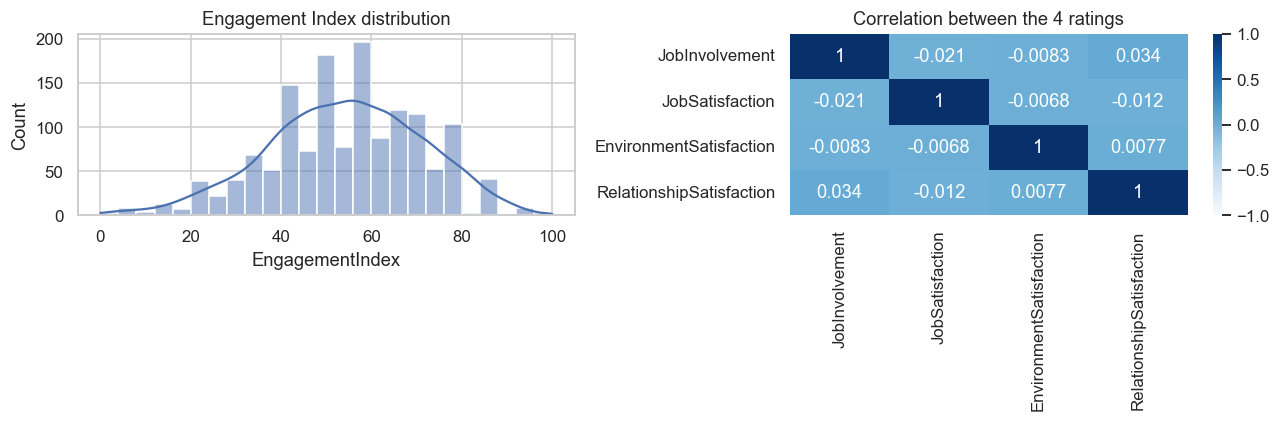

In [4]:
eng_cols = ['JobInvolvement','JobSatisfaction','EnvironmentSatisfaction','RelationshipSatisfaction']

z = (df[eng_cols] - df[eng_cols].mean()) / df[eng_cols].std()
df['EngagementZ'] = z.mean(axis=1)
df['EngagementIndex'] = 100 * (df.EngagementZ - df.EngagementZ.min()) / (df.EngagementZ.max() - df.EngagementZ.min())

print(df.EngagementIndex.describe().round(1))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df.EngagementIndex, bins=25, kde=True, ax=ax[0]); ax[0].set_title('Engagement Index distribution')
sns.heatmap(df[eng_cols].corr(), annot=True, cmap='Blues', vmin=-1, vmax=1, ax=ax[1]); ax[1].set_title('Correlation between the 4 ratings')
plt.tight_layout(); plt.show()

**Reading the heatmap:** the four ratings are almost uncorrelated (values near 0). That means they measure *different* things: someone can love their team but dislike the work. So combining them gives a broader picture than any one rating.

**Bands for alerts:** we label employees *Low* (bottom 25%), *Medium*, *High* (top 25%) engagement using quartiles.

In [5]:
q1, q3 = df.EngagementIndex.quantile([0.25, 0.75])
df['EngagementBand'] = pd.cut(df.EngagementIndex, [-1, q1, q3, 101], labels=['Low','Medium','High'])
print(f'Low < {q1:.1f} | High > {q3:.1f}')
df.EngagementBand.value_counts()

Low < 43.7 | High > 64.3


EngagementBand
Medium    734
Low       368
High      368
Name: count, dtype: int64

### Satisfaction distributions

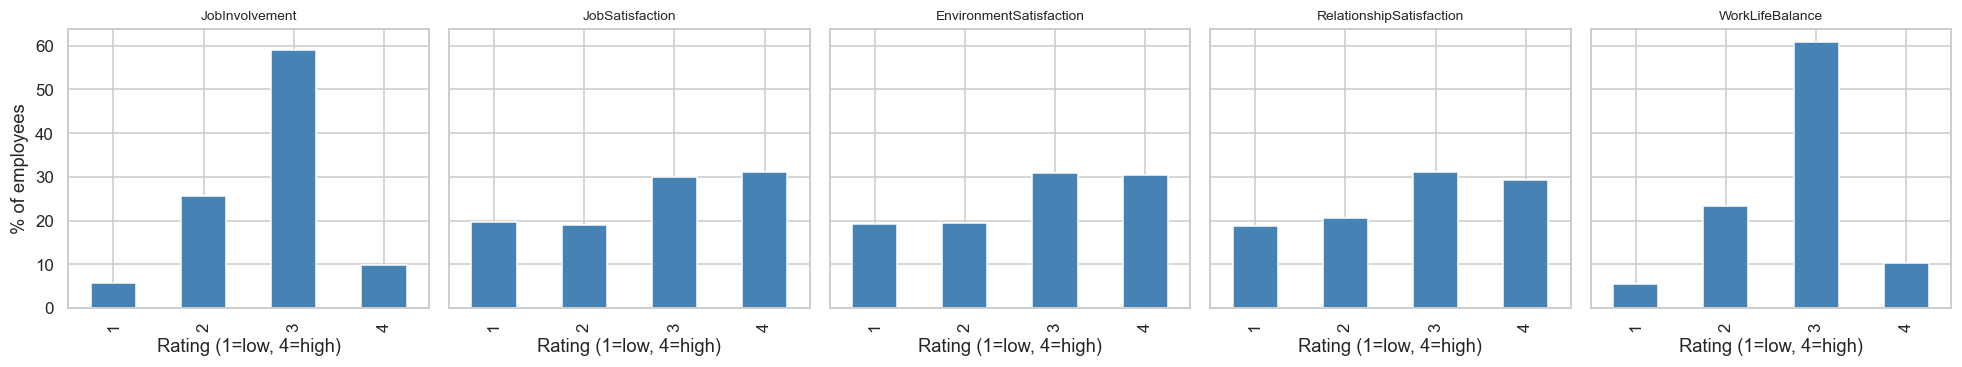

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)
for a, c in zip(axes, eng_cols + ['WorkLifeBalance']):
    df[c].value_counts(normalize=True).sort_index().mul(100).plot.bar(ax=a, color='steelblue')
    a.set_title(c, fontsize=9); a.set_xlabel('Rating (1=low, 4=high)')
axes[0].set_ylabel('% of employees'); plt.tight_layout(); plt.show()

## 3. Burnout Risk Identification
**Rule (from the project brief):** two warning signs.
- Works **OverTime** = Yes
- **Low WorkLifeBalance** (rating 1 or 2)

| Signs present | Risk level |
|---|---|
| 0 | Low |
| 1 | Medium |
| 2 | High |

In [7]:
df['OverTimeFlag']  = (df.OverTime == 'Yes').astype(int)
df['LowWLBFlag']    = (df.WorkLifeBalance <= 2).astype(int)
df['BurnoutRiskScore'] = df.OverTimeFlag + df.LowWLBFlag          # 0, 1 or 2
df['BurnoutRisk'] = df.BurnoutRiskScore.map({0:'Low', 1:'Medium', 2:'High'})
df['BurnoutRisk'] = pd.Categorical(df.BurnoutRisk, ['Low','Medium','High'], ordered=True)

summary = df.groupby('BurnoutRisk', observed=True).agg(
    employees=('Age','size'),
    avg_engagement=('EngagementIndex','mean'),
    attrition_rate=('Attrition','mean')).round(3)
summary['share_of_workforce'] = (summary.employees / len(df)).round(3)
summary

,employees,avg_engagement,attrition_rate,share_of_workforce
BurnoutRisk,,,,
Low,756,53.354,0.091,0.514
Medium,588,54.568,0.214,0.400
High,126,56.663,0.333,0.086


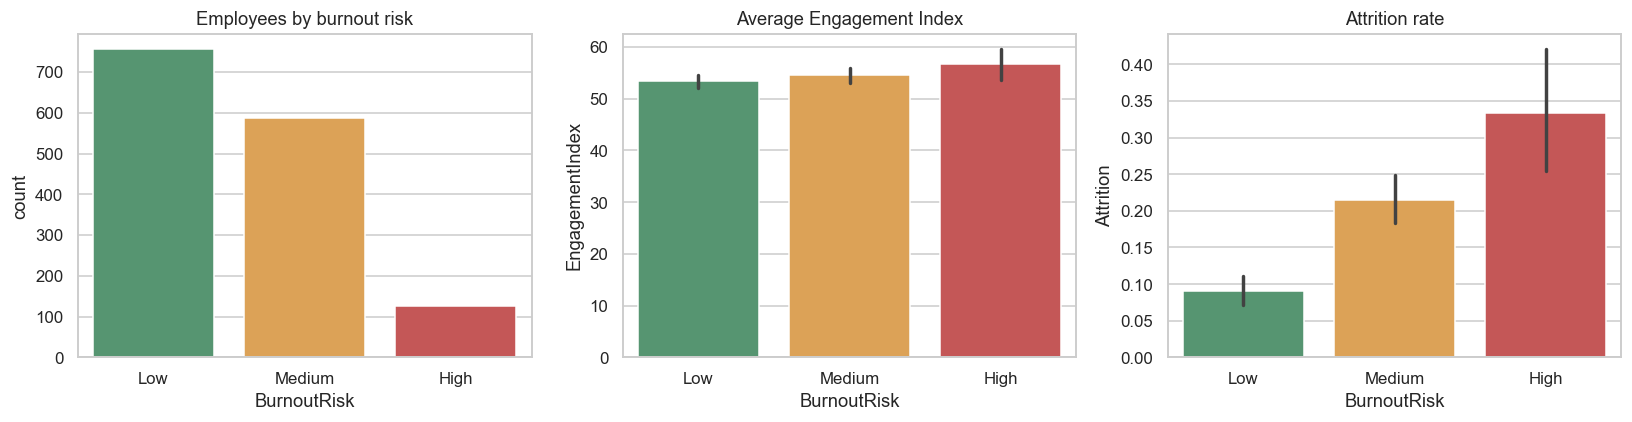

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
colors = {'Low':'#4C9F70','Medium':'#F2A541','High':'#D64545'}
order = ['Low','Medium','High']
sns.countplot(data=df, x='BurnoutRisk', order=order, palette=colors, ax=ax[0]); ax[0].set_title('Employees by burnout risk')
sns.barplot(data=df, x='BurnoutRisk', y='EngagementIndex', order=order, palette=colors, ax=ax[1]); ax[1].set_title('Average Engagement Index')
sns.barplot(data=df, x='BurnoutRisk', y='Attrition', order=order, palette=colors, ax=ax[2]); ax[2].set_title('Attrition rate')
plt.tight_layout(); plt.show()

### ⭐ Key finding
**Engagement barely changes across burnout levels (and is even slightly higher for high-risk staff), but attrition more than triples (about 9% to 33%).**

Real-world meaning: think of a hard-working employee who says they are happy and involved, but works late every night. A survey says "all good", yet they leave. **Engagement scores alone will miss burnout.** This is exactly why the two measures must be tracked together.

## 4. KPIs
| KPI | How we calculate it |
|---|---|
| Engagement Index | Standardized composite (0-100), done above |
| Burnout Risk Score | OverTime flag + Low WLB flag (0-2) |
| Work-Life Balance Index | Average WorkLifeBalance rating (1-4) |
| Satisfaction Stability Score | 100 x (1 - std of the 4 ratings / 1.5). High = consistent ratings, low = mixed feelings |
| Workload Stress Indicator | Travel (0/1/2) + OverTime (0/1) = 0 to 3 |

*Why 1.5?* The largest possible spread between four 1-4 ratings (two 1s and two 4s) has a standard deviation of about 1.73, so 1.5 keeps scores in a sensible range; we clip at 0.

In [9]:
df['SatisfactionStability'] = (100 * (1 - df[eng_cols].std(axis=1) / 1.5)).clip(0, 100)
travel_map = {'Non-Travel':0, 'Travel_Rarely':1, 'Travel_Frequently':2}
df['WorkloadStress'] = df.BusinessTravel.map(travel_map) + df.OverTimeFlag

kpis = pd.Series({
    'Engagement Index (avg, 0-100)': df.EngagementIndex.mean(),
    'Burnout Risk Score (avg, 0-2)': df.BurnoutRiskScore.mean(),
    '% High burnout risk': (df.BurnoutRisk == 'High').mean() * 100,
    'Work-Life Balance Index (avg, 1-4)': df.WorkLifeBalance.mean(),
    'Satisfaction Stability (avg, 0-100)': df.SatisfactionStability.mean(),
    'Workload Stress (avg, 0-3)': df.WorkloadStress.mean(),
}).round(2)
kpis

Engagement Index (avg, 0-100)          54.12
Burnout Risk Score (avg, 0-2)           0.57
% High burnout risk                     8.57
Work-Life Balance Index (avg, 1-4)      2.76
Satisfaction Stability (avg, 0-100)    36.93
Workload Stress (avg, 0-3)              1.37
dtype: float64

## 5. Workload & Stress Analysis
We compare engagement *and* attrition across overtime, travel and commute. We add a statistical test to check the differences are real and not luck.

*Mann-Whitney U test:* compares two groups without assuming a bell-curve shape. A **p-value below 0.05** means the difference is unlikely to be chance.

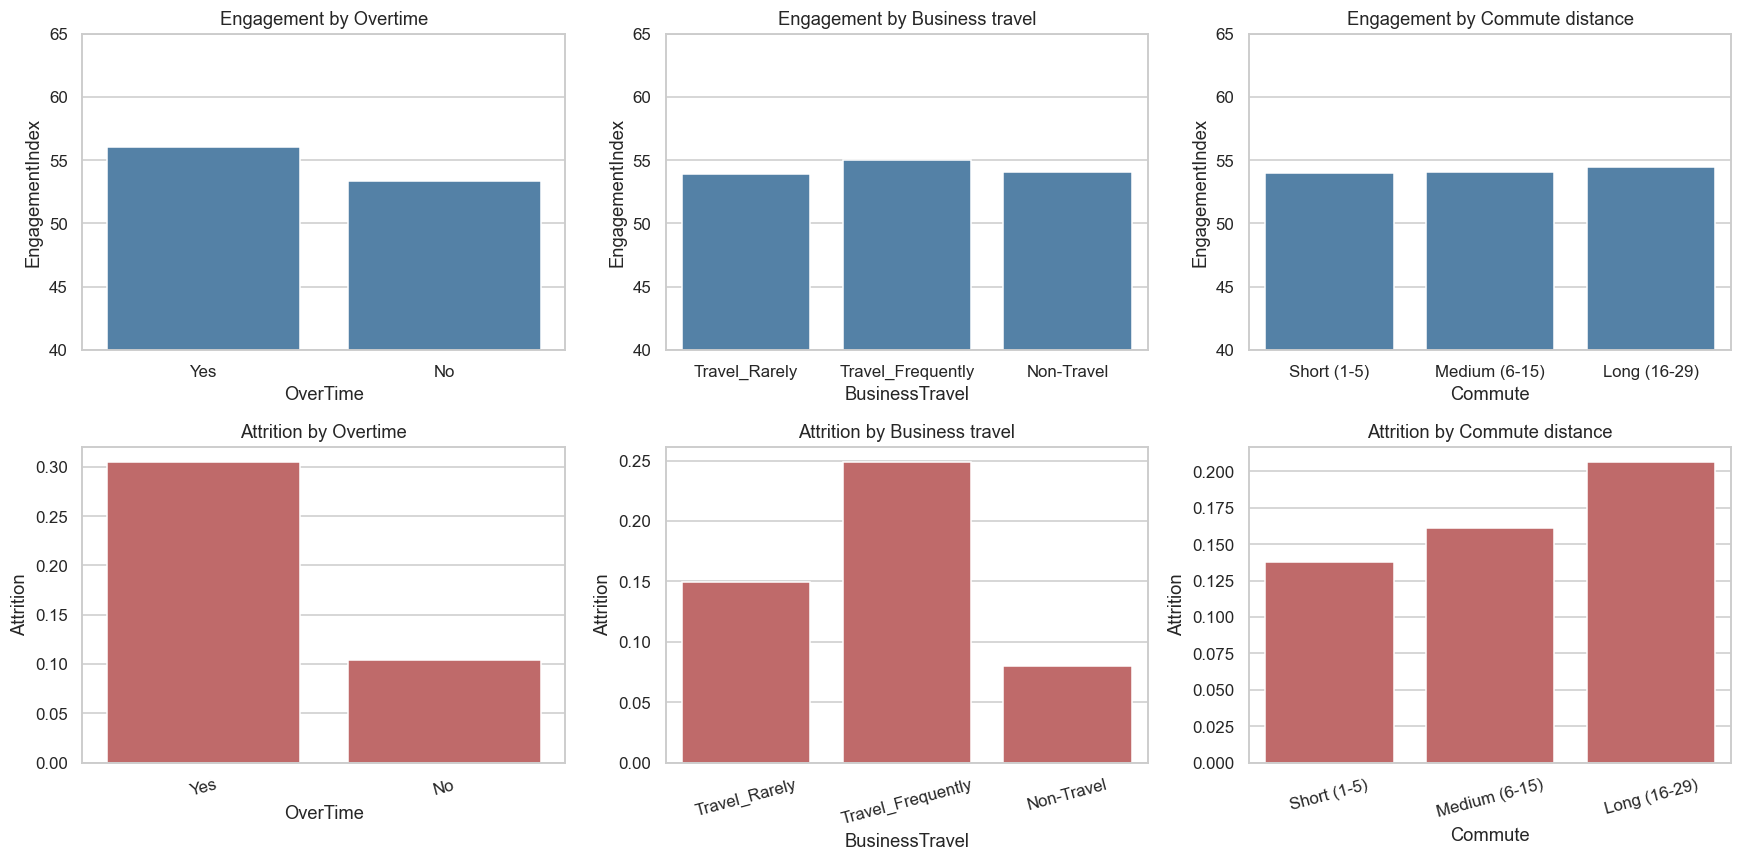

Engagement  OT vs non-OT: 56.0 vs 53.4 | p = 0.0023
Attrition   OT vs non-OT: 30.5% vs 10.4%


In [10]:
df['Commute'] = pd.cut(df.DistanceFromHome, [0, 5, 15, 30], labels=['Short (1-5)','Medium (6-15)','Long (16-29)'])

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for j, (col, title) in enumerate([('OverTime','Overtime'), ('BusinessTravel','Business travel'), ('Commute','Commute distance')]):
    sns.barplot(data=df, x=col, y='EngagementIndex', ax=ax[0, j], errorbar=None, color='steelblue'); ax[0, j].set_title(f'Engagement by {title}')
    sns.barplot(data=df, x=col, y='Attrition', ax=ax[1, j], errorbar=None, color='indianred'); ax[1, j].set_title(f'Attrition by {title}')
    ax[0, j].set_ylim(40, 65); ax[1, j].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

ot = df[df.OverTime=='Yes']; no = df[df.OverTime=='No']
print('Engagement  OT vs non-OT:', round(ot.EngagementIndex.mean(),1), 'vs', round(no.EngagementIndex.mean(),1),
      '| p =', f"{stats.mannwhitneyu(ot.EngagementIndex, no.EngagementIndex).pvalue:.4f}")
print('Attrition   OT vs non-OT:', f'{ot.Attrition.mean():.1%} vs {no.Attrition.mean():.1%}')

,employees,engagement,attrition
WorkloadStress,,,
0,115,54.159,0.043
1,783,53.199,0.101
2,486,54.933,0.241
3,86,57.915,0.419


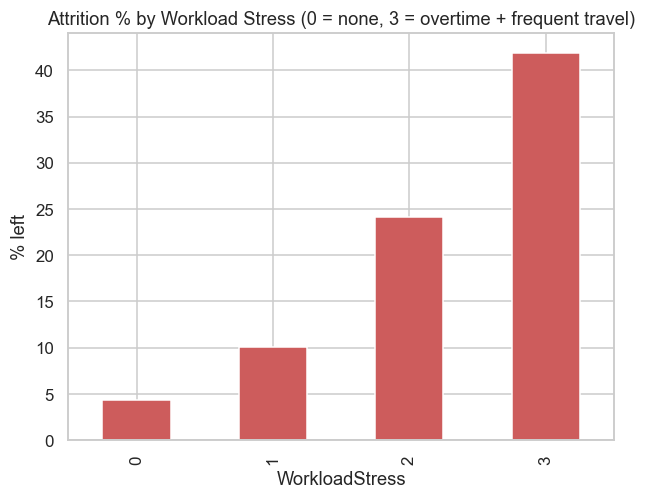

In [11]:
# Workload stress indicator vs attrition and engagement
ws = df.groupby('WorkloadStress').agg(employees=('Age','size'), engagement=('EngagementIndex','mean'), attrition=('Attrition','mean')).round(3)
display(ws)
ws.attrition.mul(100).plot.bar(color='indianred', title='Attrition % by Workload Stress (0 = none, 3 = overtime + frequent travel)'); plt.ylabel('% left'); plt.show()

In [12]:
# Where do overtime and low work-life balance overlap? (4 groups)
combo = df.groupby(['OverTime','LowWLBFlag']).agg(employees=('Age','size'), engagement=('EngagementIndex','mean'), attrition=('Attrition','mean')).round(3)
combo.index = combo.index.set_names(['OverTime','LowWLB (<=2)'])
combo

employees  engagement  attrition
OverTime LowWLB (<=2)                                  
No       0                   756      53.354      0.091
         1                   298      53.389      0.138
Yes      0                   290      55.780      0.293
         1                   126      56.663      0.333

**Takeaways**
- **Overtime is the strongest single warning sign:** attrition about 31% vs 10% without overtime.
- Overtime staff are *not* less engaged, which again shows engagement surveys can hide stress.
- Frequent travellers leave at about 25% vs 8% for non-travellers; commute adds a smaller effect.
- Stress stacks: attrition rises steadily as the Workload Stress score goes up.
- Low work-life balance alone has a smaller effect than overtime alone; the combination is worst.

## 6. Career-Stage Engagement Analysis
We look at engagement and attrition by job level, tenure and time in role, then test for **stagnation**: employees who have been in the same role *and* without promotion for 4+ years.

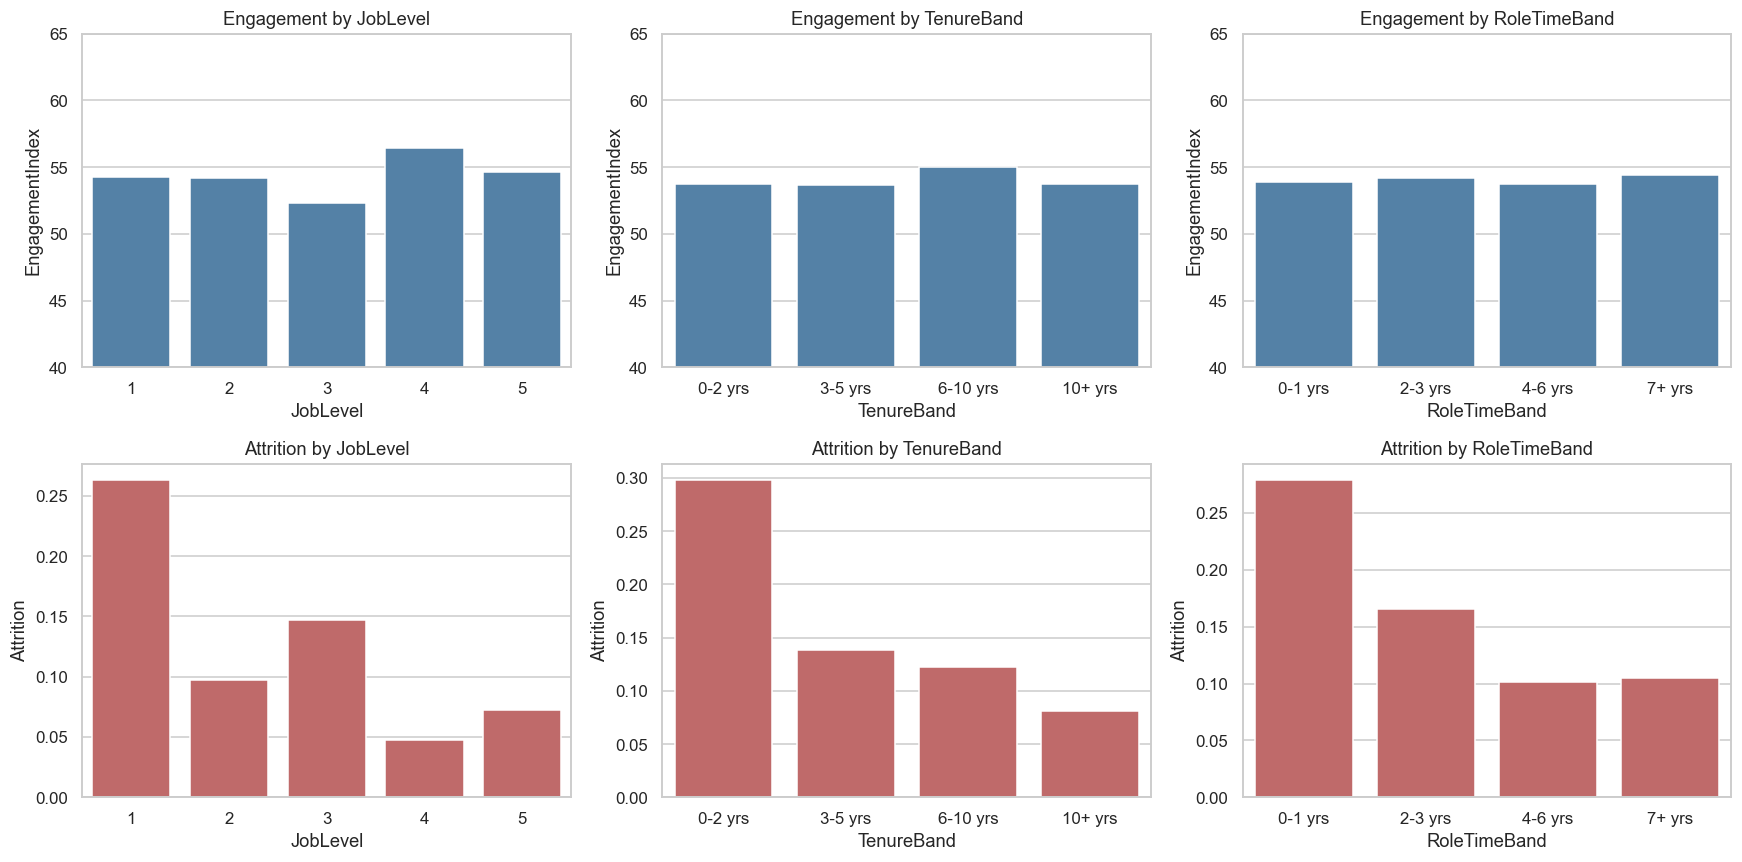

In [13]:
df['TenureBand'] = pd.cut(df.YearsAtCompany, [-1, 2, 5, 10, 40], labels=['0-2 yrs','3-5 yrs','6-10 yrs','10+ yrs'])
df['RoleTimeBand'] = pd.cut(df.YearsInCurrentRole, [-1, 1, 3, 6, 20], labels=['0-1 yrs','2-3 yrs','4-6 yrs','7+ yrs'])

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for j, col in enumerate(['JobLevel','TenureBand','RoleTimeBand']):
    sns.barplot(data=df, x=col, y='EngagementIndex', ax=ax[0, j], errorbar=None, color='steelblue'); ax[0, j].set_ylim(40, 65); ax[0, j].set_title(f'Engagement by {col}')
    sns.barplot(data=df, x=col, y='Attrition', ax=ax[1, j], errorbar=None, color='indianred'); ax[1, j].set_title(f'Attrition by {col}')
plt.tight_layout(); plt.show()

In [14]:
role = df.groupby('JobRole').agg(employees=('Age','size'), engagement=('EngagementIndex','mean'),
        pct_high_burnout=('BurnoutRisk', lambda s: (s=='High').mean()*100), attrition=('Attrition','mean')).round(2).sort_values('engagement')
role

,employees,engagement,pct_high_burnout,attrition
JobRole,,,,
Sales Representative,83,52.43,7.23,0.40
Research Director,80,52.49,8.75,0.02
Laboratory Technician,259,53.18,9.27,0.24
Human Resources,52,53.56,3.85,0.23
Sales Executive,326,53.67,8.90,0.17
Manufacturing Director,145,54.83,7.59,0.07
Healthcare Representative,131,54.86,6.11,0.07
Research Scientist,292,55.29,10.96,0.16
Manager,102,55.64,6.86,0.05


In [15]:
# Stagnation: 4+ years in role AND 4+ years since last promotion
df['Stagnant'] = ((df.YearsInCurrentRole >= 4) & (df.YearsSinceLastPromotion >= 4)).astype(int)
st = df.groupby('Stagnant').agg(employees=('Age','size'), engagement=('EngagementIndex','mean'),
        avg_stability=('SatisfactionStability','mean'), attrition=('Attrition','mean')).round(3)
print(st)
a, b = df[df.Stagnant==1].EngagementIndex, df[df.Stagnant==0].EngagementIndex
print('Mann-Whitney p-value (engagement):', round(stats.mannwhitneyu(a, b).pvalue, 3))
print('Correlation: YearsSinceLastPromotion vs Engagement =', round(df.YearsSinceLastPromotion.corr(df.EngagementIndex), 3))

          employees  engagement  avg_stability  attrition
Stagnant                                                 
0              1185      54.074         37.279      0.170
1               285      54.331         35.472      0.123
Mann-Whitney p-value (engagement): 0.92
Correlation: YearsSinceLastPromotion vs Engagement = 0.004


**Honest finding:** in this dataset, stagnation is **not** linked to lower engagement (p is large, correlation near 0). Stagnant staff are not less engaged and actually leave a bit *less*. So we should **not** claim "stagnation causes disengagement" here.

The real career-stage risk is **early tenure and entry level**: employees with 0-2 years and Job Level 1 have the highest attrition (about 30% and 26%). Sales Representatives, Laboratory Technicians and HR have the highest attrition by role.

## 7. Engagement vs Attrition (Contextual Only)
We *compare* people who stayed with those who left. This shows context; it is not a prediction model.

,Stayed,Left,Gap
JobInvolvement,2.77,2.52,-0.25
JobSatisfaction,2.78,2.47,-0.31
EnvironmentSatisfaction,2.77,2.46,-0.31
RelationshipSatisfaction,2.73,2.60,-0.13
EngagementIndex,55.58,46.57,-9.01
WorkLifeBalance,2.78,2.66,-0.12
SatisfactionStability,37.33,34.82,-2.51


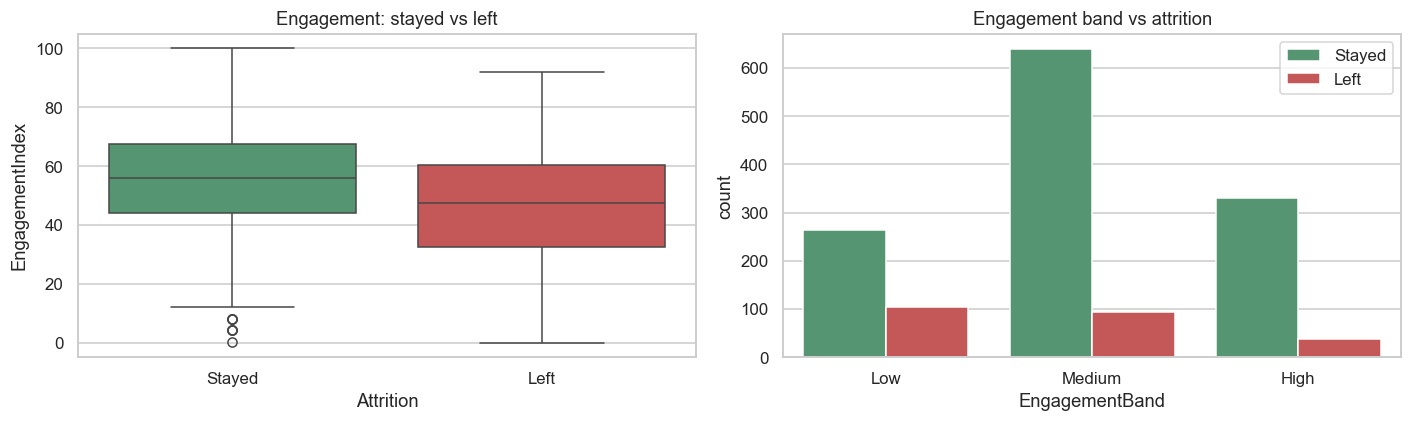

Mann-Whitney p = 3.5513395493278506e-11
EngagementBand
Low       0.283
Medium    0.129
High      0.103
Name: Attrition, dtype: float64


In [16]:
cmp = df.groupby('Attrition')[eng_cols + ['EngagementIndex','WorkLifeBalance','SatisfactionStability']].mean().T.round(2)
cmp.columns = ['Stayed','Left']; cmp['Gap'] = (cmp.Left - cmp.Stayed).round(2)
display(cmp)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x='Attrition', y='EngagementIndex', ax=ax[0], palette=['#4C9F70','#D64545']); ax[0].set_xticklabels(['Stayed','Left']); ax[0].set_title('Engagement: stayed vs left')
sns.countplot(data=df, x='EngagementBand', hue='Attrition', ax=ax[1], palette=['#4C9F70','#D64545']); ax[1].set_title('Engagement band vs attrition'); ax[1].legend(['Stayed','Left'])
plt.tight_layout(); plt.show()

print('Mann-Whitney p =', stats.mannwhitneyu(df[df.Attrition==1].EngagementIndex, df[df.Attrition==0].EngagementIndex).pvalue)
print(df.groupby('EngagementBand', observed=True).Attrition.mean().round(3))

**Takeaway:** people who left scored about 9 points lower on the Engagement Index (statistically significant), and attrition falls as engagement rises. So engagement *does* matter, but **it does not catch burnout**, which is why we use both signals.

## 8. Manager Action List & Recommendations
We build a **priority score** so managers know whom to talk to first.

`Priority = 2 x (High burnout) + 1 x (Medium burnout) + 1 x (Low engagement band) + 1 x (Frequent travel) + 1 x (Entry level & tenure <= 2 years)`

In [17]:
df['PriorityScore'] = (2*(df.BurnoutRisk=='High') + 1*(df.BurnoutRisk=='Medium') + 1*(df.EngagementBand=='Low')
                       + 1*(df.BusinessTravel=='Travel_Frequently') + 1*((df.JobLevel==1) & (df.YearsAtCompany<=2))).astype(int)
print(df.groupby('PriorityScore').agg(employees=('Age','size'), attrition=('Attrition','mean')).round(3))

cols = ['Department','JobRole','JobLevel','YearsAtCompany','OverTime','WorkLifeBalance','BusinessTravel','EngagementIndex','BurnoutRisk','PriorityScore']
df.sort_values(['PriorityScore','EngagementIndex'], ascending=[False, True])[cols].head(15).round(1)

               employees  attrition
PriorityScore                      
0                    377      0.034
1                    622      0.101
2                    349      0.272
3                    109      0.514
4                     12      0.750
5                      1      1.000


,Department,JobRole,JobLevel,YearsAtCompany,OverTime,WorkLifeBalance,BusinessTravel,EngagementIndex,BurnoutRisk,PriorityScore
1060,Research & Development,Laboratory Technician,1,0,Yes,2,Travel_Frequently,40.4,High,5
106,Research & Development,Research Director,5,8,Yes,2,Travel_Frequently,24.3,High,4
157,Research & Development,Research Scientist,1,1,Yes,2,Travel_Rarely,28.1,High,4
915,Research & Development,Laboratory Technician,1,2,No,1,Travel_Frequently,36.0,Medium,4
93,Research & Development,Healthcare Representative,3,10,Yes,2,Travel_Frequently,36.2,High,4
1068,Research & Development,Laboratory Technician,1,0,No,2,Travel_Frequently,36.2,Medium,4
463,Research & Development,Laboratory Technician,1,1,Yes,1,Travel_Rarely,39.6,High,4
1438,Sales,Sales Representative,1,1,No,2,Travel_Frequently,40.3,Medium,4
838,Sales,Sales Executive,4,21,Yes,2,Travel_Frequently,40.3,High,4
1332,Research & Development,Research Scientist,1,1,Yes,2,Travel_Frequently,59.6,High,4


The priority score separates risk well: attrition climbs steadily as the score goes up, so it is a useful screening tool for managers.

### Recommendations
1. **Cap and monitor overtime.** Overtime is the clearest driver (31% vs 10% attrition). Flag teams where more than about 30% work overtime regularly.
2. **Track burnout beside engagement.** Add overtime and work-life-balance flags to the survey dashboard, because engagement alone hides this risk.
3. **Protect the first two years.** Run onboarding check-ins, mentoring and early-career growth plans for Level 1 staff (about 30% attrition at 0-2 years).
4. **Target Sales Representatives, Lab Technicians and HR** with role-specific workload reviews.
5. **Manage travel load.** Rotate frequent travellers and cap consecutive travel weeks.
6. **Use the Manager Action Panel** (Streamlit app) monthly to review the top-priority employees.

### Limitations
- The data is a single snapshot, so we show *associations*, not proven causes.
- Engagement items are weakly related to each other, so the index is a broad summary, not a deep psychological measure.
- The burnout rule is a simple screen (from the brief); a richer model would use more signals.